# Fossil-fuel potential self-generation near U.S. census tracts
**2023 · 48 contiguous states and the District of Columbia**

Use this companion alongside DataCleaning.ipynb. Run that notebook through the national plant export once. This notebook downloads public ACS bulk tables and Census geography without an API key; cached downloads are reused. It produces a tract file, a tract–plant distance file, state summaries, maps, and pooled two-part county random-intercept models. Every tract has equal weight in the models. Resident comparisons use ACS counts.

Miniforge dependencies: pandas, numpy, scipy, statsmodels, pyarrow, scikit-learn, geopandas, matplotlib, threadpoolctl, requests and ipykernel. Public data downloads require internet on the first run. Sources and modeling choices are recorded below.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.neighbors import BallTree
from scipy import sparse
from threadpoolctl import threadpool_limits
import statsmodels.formula.api as smf
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
import requests

# Use None for all contiguous states + DC, or e.g. ["CA","AZ","NV"].
SELECT_STATES = None
raw = Path("data/raw")
raw.mkdir(parents=True,exist_ok=True)
def cached(name,url):
    path = raw/name
    if not path.exists():
        tmp = path.with_suffix(".part")
        with requests.get(url,stream=True,timeout=180) as resp:
            resp.raise_for_status()
            with tmp.open("wb") as f:
                for chunk in resp.iter_content(2**20):
                    f.write(chunk)
        tmp.replace(path)
    return path
census = "https://www2.census.gov"
shape = cached("cb_2023_us_state_20m.zip",census+"/geo/tiger/GENZ2023/shp/cb_2023_us_state_20m.zip")
states = gpd.read_file(shape)
states = states.loc[states.STATEFP.astype(int).le(56) & ~states.STUSPS.isin(["AK","HI"])].copy()
assert len(states)==49
if SELECT_STATES is not None:
    assert SELECT_STATES and set(SELECT_STATES)<=set(states.STUSPS)
    states = states.loc[states.STUSPS.isin(SELECT_STATES)].copy()
out = Path("outputs")/("selfgen_conus_dc" if SELECT_STATES is None else "selfgen_"+"_".join(sorted(states.STUSPS)))
out.mkdir(parents=True,exist_ok=True)
codes = dict(zip(states.STATEFP,states.STUSPS))
plants = pd.read_parquet("data/processed/potential_selfgen_fossil_plants_2023.parquet")
assert plants.plant_id_eia.is_unique
def save_table(frame,name):
    frame.to_csv(out/f"{name}.csv",index=False)
    display(frame.round(3))
def save_fig(fig,name):
    fig.tight_layout()
    fig.savefig(out/f"{name}.png",dpi=170,bbox_inches="tight")
    plt.show()
    plt.close(fig)

## Assemble tract demographics and geography
Use ACS poverty-universe and below-poverty counts plus total population. Negative estimate placeholders and undefined poverty rates stay missing. Coordinates are 2020 population centers. Connecticut changed county-equivalent identifiers; accept tract matches across vintages only if old and new polygons overlap at least 99% in both directions. Report unmatched tracts and leave their proximity unknown.

In [2]:
def acs_table(name,columns):
    url = f"{census}/programs-surveys/acs/summary_file/2023/table-based-SF/data/5YRData/acsdt5y2023-{name}.dat"
    parts = []
    for chunk in pd.read_csv(cached(name+".dat",url),sep="|",usecols=["GEO_ID",*columns],chunksize=100000):
        ids = chunk.GEO_ID
        parts.append(chunk.loc[ids.str.startswith("1400000US") & ids.str[9:11].isin(codes)].copy())
    return pd.concat(parts,ignore_index=True).rename(columns=columns)
t = acs_table("b17001",{"B17001_E001":"universe","B17001_E002":"below"}).merge(
    acs_table("b01003",{"B01003_E001":"population"}),on="GEO_ID",validate="one_to_one")
t["geoid"] = t.GEO_ID.str[-11:]
t["county"] = t.geoid.str[:5]
t["state"] = t.geoid.str[:2].map(codes)
assert set(t.state)==set(codes.values())
for col in ["universe","below","population"]:
    t[col] = t[col].where(t[col]>=0)
t["above"] = t.universe-t.below
t["poverty"] = 100*t.below/t.universe.where(t.universe>0)
cent = pd.read_csv(cached("centers2020.txt",census+"/geo/docs/reference/cenpop2020/tract/CenPop2020_Mean_TR.txt"),
                   dtype={"STATEFP":str,"COUNTYFP":str,"TRACTCE":str})
cent = cent.loc[cent.STATEFP.isin(codes) & cent.POPULATION.gt(0)].copy()
cent["geoid"] = cent.STATEFP+cent.COUNTYFP+cent.TRACTCE
if "09" in codes:
    shapes = []
    for y in (2020,2023):
        name = f"tl_{y}_09_tract.zip"
        frame = gpd.read_file(cached(name,f"{census}/geo/tiger/TIGER{y}/TRACT/{name}")).to_crs(5070)
        frame = frame[["GEOID","geometry"]].rename(columns={"GEOID":f"id{y}"})
        frame[f"area{y}"] = frame.area
        shapes.append(frame)
    cross = gpd.overlay(*shapes,how="intersection",keep_geom_type=True)
    overlap = cross.area
    cross = cross.loc[(overlap/cross.area2020>=.99) & (overlap/cross.area2023>=.99)]
    assert cross.id2020.is_unique and cross.id2023.is_unique
    ct = cent.STATEFP.eq("09")
    cent.loc[ct,"geoid"] = cent.loc[ct,"geoid"].map(cross.set_index("id2020").id2023)
t = t.merge(cent.dropna(subset=["geoid"])[["geoid","LATITUDE","LONGITUDE"]],how="left",validate="one_to_one")
gaz = pd.read_csv(cached("gaz_tracts.zip",census+"/geo/docs/maps-data/data/gazetteer/2023_Gazetteer/2023_Gaz_tracts_national.zip"),sep="\t",usecols=["GEOID","ALAND"],dtype={"GEOID":str})
t = t.merge(gaz.rename(columns={"GEOID":"geoid"}),on="geoid",how="left",validate="one_to_one")

## Nearby facilities
Use the national plant list across all state lines. A zero means no mapped qualifying plant at that distance. A tract with no center or a nearby plant with unknown MW retains unknown capacity. The survey does not cover foreign facilities near international borders.

In [3]:
mapped = t.dropna(subset=["LATITUDE","LONGITUDE"])
sites = plants.loc[plants.coordinates_valid.fillna(False)].reset_index(drop=True)
tree = BallTree(np.radians(sites[["latitude","longitude"]].astype(float)),metric="haversine")
idx,dist = tree.query_radius(np.radians(mapped[["LATITUDE","LONGITUDE"]]),r=10/6371,return_distance=True)
pairs = pd.DataFrame({"geoid":np.repeat(mapped.geoid.to_numpy(),[len(x) for x in idx]),
                      "plant_row":np.concatenate(idx),"km":np.concatenate(dist)*6371})
pairs = pairs.join(sites[["plant_id_eia","plant_name_eia","state","fossil_capacity_mw"]].rename(columns={"state":"plant_state"}),on="plant_row")
assert not pairs.duplicated(["geoid","plant_id_eia"]).any()
pairs.drop(columns="plant_row").to_parquet(out/"pairs_10km.parquet",index=False)
for radius in (2,5,10):
    grp = pairs.loc[pairs.km.le(radius)].groupby("geoid").fossil_capacity_mw
    n = t.geoid.map(grp.size()).fillna(0).where(t.LATITUDE.notna())
    t[f"n{radius}"] = n
    total = t.geoid.map(grp.sum()).where(n.ne(0),0)
    t[f"mw{radius}"] = total.mask(n.gt(t.geoid.map(grp.count()).fillna(0)))
assert t.geoid.is_unique
t.to_parquet(out/"tracts_2023.parquet",index=False)

## State comparisons and pooled population estimates
Summarize the share of tract centers within 5 km and the proportion of each resident poverty group living in those tracts. Pooled percentages aggregate numerators and denominators. Unknown proximity is excluded. A gap is measured in percentage points, below minus at/above poverty.

,state,tracts,mapped,missing_center,positive_5km,pct_near,below_pct,above_pct,gap_pp
0,Pooled,83762,83219,543,9415,11.314,13.993,10.584,3.409
1,AL,1437,1434,3,25,1.743,2.174,0.905,1.269
2,AR,823,823,0,19,2.309,3.881,1.956,1.925
3,AZ,1765,1753,12,74,4.221,7.333,3.553,3.779
4,CA,9129,9097,32,1593,17.511,16.759,16.519,0.240
5,CO,1447,1439,8,38,2.641,4.764,2.036,2.728
6,CT,884,871,13,272,31.228,43.204,28.481,14.723
7,DC,206,206,0,149,72.330,65.747,71.449,-5.702
8,DE,262,258,4,3,1.163,0.718,1.300,-0.581
9,FL,5160,5093,67,107,2.101,3.312,1.831,1.482


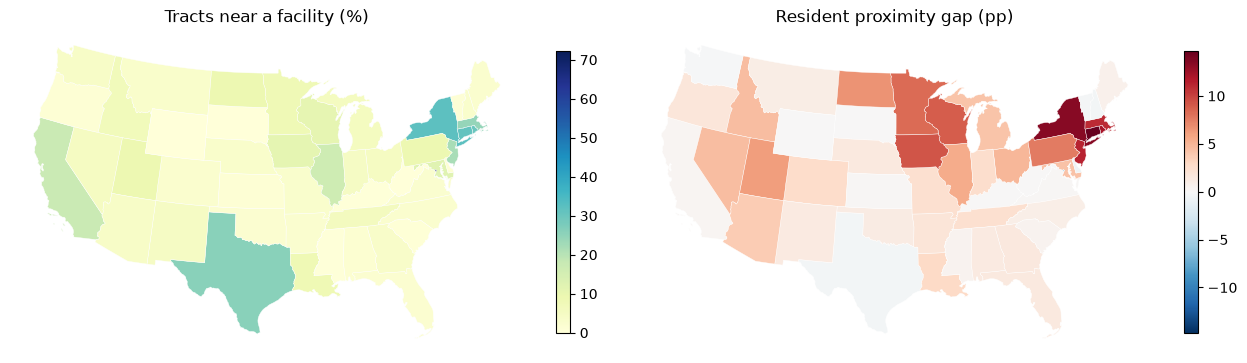

In [4]:
def summary(s,label):
    eligible = s.dropna(subset=["n5","below","above"])
    near = eligible.n5.gt(0)
    shares = 100*eligible.loc[near,["below","above"]].sum()/eligible[["below","above"]].sum()
    return dict(state=label,tracts=len(s),mapped=int(s.n5.count()),missing_center=int(s.n5.isna().sum()),
                positive_5km=int(s.mw5.gt(0).sum()),pct_near=100*s.n5.dropna().gt(0).mean(),
                below_pct=shares.below,above_pct=shares.above,gap_pp=shares.below-shares.above)
rows = [summary(s,k) for k,s in t.groupby("state")]
state_table = pd.DataFrame(rows)
overall = pd.DataFrame([summary(t,"Pooled")])
save_table(pd.concat([overall,state_table],ignore_index=True),"state_comparison")
maps = states.merge(state_table,left_on="STUSPS",right_on="state").to_crs(5070)
fig,axs = plt.subplots(1,2,figsize=(13,5))
from matplotlib.colors import TwoSlopeNorm
mx = max(.01,state_table.gap_pp.abs().max())
for ax,col,title,cmap,opts in [(axs[0],"pct_near","Tracts near a facility (%)","YlGnBu",{}),
                                (axs[1],"gap_pp","Resident proximity gap (pp)","RdBu_r",{"norm":TwoSlopeNorm(0,-mx,mx)})]:
    maps.plot(column=col,ax=ax,cmap=cmap,legend=True,edgecolor="white",linewidth=.3,legend_kwds={"shrink":.6},**opts)
    ax.set_title(title); ax.set_axis_off()
save_fig(fig,"state_maps")

## Pooled poverty associations
State fixed effects adjust for different state baselines. County-equivalent random intercepts allow tracts from one county to cluster. Presence uses a sparse county matrix for Bayesian logistic regression; reported intervals are approximate variational credible intervals. Positive log MW uses maximum-likelihood linear mixed regression with Wald confidence intervals. These fits estimate shared slopes. The positive fit only represents jurisdictions with positive tracts. Density sensitivity uses an identical complete-case baseline. County grouping may leave residual dependence between tracts that share a plant.

,km,density,matched_density_sample,tracts,counties,positive,positive_states,positive_counties,presence_icc,amount_icc,odds_ratio,or_low,or_high,amount_pct,amount_low,amount_high
0,2,False,False,82813,3109,2280,42,209,0.541,0.490,1.454,1.412,1.497,5.614,2.527,8.794
1,5,False,False,82813,3109,9331,46,293,0.715,0.580,1.380,1.350,1.411,0.037,-1.617,1.719
2,10,False,False,82813,3109,19559,48,370,0.807,0.587,1.484,1.450,1.519,0.023,-1.228,1.290
3,5,False,True,82813,3109,9331,46,293,0.715,0.580,1.380,1.350,1.411,0.037,-1.617,1.719
4,5,True,True,82813,3109,9331,46,293,0.705,0.581,1.162,1.135,1.188,-0.726,-2.416,0.993


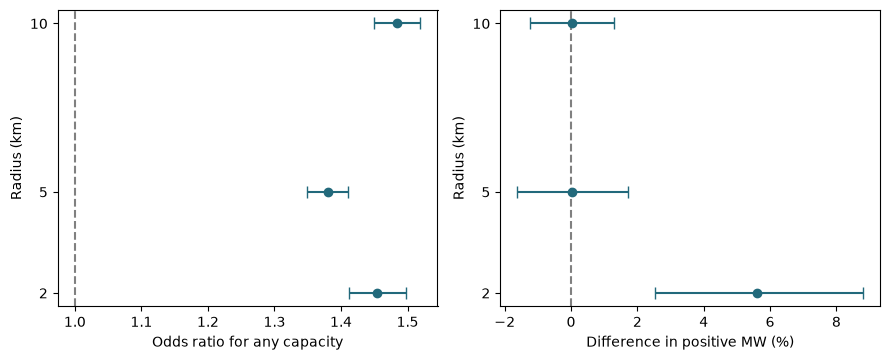

In [5]:
# National-scale implementation of the same mean-field logistic county model.
# Evaluate each quadrature node on the rows, then multiply by sparse design matrices once.
from scipy.optimize import minimize
from scipy.special import expit
from numpy.polynomial.legendre import leggauss

def county_logit(y, X, ci):
    design = sparse.csr_matrix(X.to_numpy(dtype=float))
    square = design.power(2)
    y = y.to_numpy(dtype=float)
    groups = np.bincount(ci)
    nf, ng = design.shape[1],len(groups)
    nodes, weights = leggauss(10)
    nodes *= 5
    weights *= 5*np.exp(-nodes**2/2)/np.sqrt(2*np.pi)
    # Order: fixed effects, log county SD, county intercepts; then their log posterior SDs.
    k = nf+1+ng
    info = np.r_[np.asarray(square.sum(axis=0)).ravel()/5+1,ng*2,groups/5+1]
    step = np.r_[1/np.sqrt(info),np.ones(k)*.65]
    def objective(z):
        theta = z*step
        m, logs = theta[:k],theta[k:]
        s = np.exp(logs)
        b,h,u = m[:nf],m[nf],m[nf+1:]
        sb,sh,su = s[:nf],s[nf],s[nf+1:]
        eta = design@b + u[ci]
        se = np.sqrt(square@(sb**2) + su[ci]**2)
        objective_value = y@eta
        grad_eta,grad_se = y.copy(),np.zeros_like(y)
        for node,w in zip(nodes,weights):
            q = eta+se*node
            objective_value -= w*np.logaddexp(0,q).sum()
            prob = w*expit(q)
            grad_eta -= prob
            grad_se -= node*prob
        precision = np.exp(2*(sh**2-h))
        second = (u@u+su@su)*precision
        objective_value += logs.sum()-second/2-ng*h-(b@b+sb@sb)/8-(h*h+sh*sh)/.5
        se_grad = grad_se/se
        gm = np.r_[design.T@grad_eta-b/4,second-ng-4*h,
                   np.bincount(ci,weights=grad_eta)-u*precision]
        glogs = np.r_[(square.T@se_grad-.25)*sb**2,(-2*second-4)*sh**2,
                      (np.bincount(ci,weights=se_grad)-precision)*su**2]+1
        return -objective_value,-np.r_[gm,glogs]*step
    start = np.r_[np.zeros(k),-.5*np.log(info)]/step
    result = minimize(objective,start,jac=True,method="L-BFGS-B",
                      options={"maxiter":1000,"ftol":1e-11,"gtol":1e-5})
    if not result.success: raise RuntimeError(result.message)
    theta = result.x*step
    j = X.columns.get_loc("pov")
    return theta[j],np.exp(theta[k+j]),theta[nf]

def fit_models(radius,adjust_density=False,common_density=False):
    col = f"mw{radius}"
    a = t.dropna(subset=[col,"poverty","population"]).loc[lambda f:f.population.gt(0)].copy()
    if adjust_density or common_density:
        a = a.loc[a.ALAND.gt(0)].copy()
        a["density"] = np.log(a.population/(a.ALAND/1e6))
        a["density"] = (a.density-a.density.mean())/a.density.std()
    a["pov"] = (a.poverty-a.poverty.mean())/10
    a["lp"] = np.log(a.population)-np.log(a.population).mean()
    a["any_mw"] = a[col].gt(0).astype(int)
    fixed = ["pov","lp"] + (["density"] if adjust_density else [])
    X = pd.concat([a[fixed],pd.get_dummies(a.state,drop_first=True,dtype=float)],axis=1)
    X.insert(0,"Intercept",1.)
    ci, counties = pd.factorize(a.county)
    b,sd,county_log_sd = county_logit(a.any_mw,X,ci)
    pos = a[a.any_mw.eq(1)].copy()
    pos["log_mw"] = np.log(pos[col])
    if pos.county.nunique()<2: raise ValueError("Insufficient positive counties for amount model")
    formula = "log_mw ~ "+" + ".join(fixed)+" + C(state)"
    amount = smf.mixedlm(formula,pos,groups=pos.county).fit(reml=False,method="powell",disp=False)
    if not amount.converged: raise RuntimeError("Amount model failed to converge")
    val,lo,hi = 100*np.expm1([amount.fe_params.pov,*amount.conf_int().loc["pov"]])
    return dict(km=radius,density=adjust_density,matched_density_sample=common_density or adjust_density,
                tracts=len(a),counties=len(counties),positive=len(pos),positive_states=pos.state.nunique(),
                positive_counties=pos.county.nunique(),presence_icc=expit(2*county_log_sd-np.log(np.pi**2/3)),
                amount_icc=amount.cov_re.iloc[0,0]/(amount.cov_re.iloc[0,0]+amount.scale),odds_ratio=np.exp(b),or_low=np.exp(b-1.96*sd),
                or_high=np.exp(b+1.96*sd),amount_pct=val,amount_low=lo,amount_high=hi)
with threadpool_limits(limits=1):
    models = []
    for r in [2,5,10]:
        models.append(fit_models(r))
    models.extend([fit_models(5,common_density=True),fit_models(5,adjust_density=True)])
fits = pd.DataFrame(models)
save_table(fits,"pooled_models")
fig,axs = plt.subplots(1,2,figsize=(9,3.7))
z = fits.iloc[:3]
for ax,c,lo,hi,ref,title in [(axs[0],"odds_ratio","or_low","or_high",1,"Odds ratio for any capacity"),
                             (axs[1],"amount_pct","amount_low","amount_high",0,"Difference in positive MW (%)")]:
    ax.errorbar(z[c],z.km,xerr=[z[c]-z[lo],z[hi]-z[c]],fmt="o",capsize=4,color="#22697b")
    ax.axvline(ref,ls="--",color="grey"); ax.set(xlabel=title,ylabel="Radius (km)",yticks=[2,5,10])
save_fig(fig,"radius_models")

## How do results differ across individual states?
The figure shows the raw within-state gap in resident proximity, in percentage points. Dot sizes are constant so the District of Columbia and less populous states can be read. Columns have independent state lists and share the same horizontal scale. Small numbers of contributing plants can influence a state's result. The table distinguishes mapped qualifying sites from their generating scale.

,state,tracts,mapped,missing_center,positive_5km,pct_near,below_pct,above_pct,gap_pp,contributing_sites,tract_site_pairs,mean_sites_positive,median_mw_positive,mean_mw_per_site,tracts_with_out_of_state_site
0,AL,1437,1434,3,25,1.743,2.174,0.905,1.269,5,25,1.000,50.00,31.984,0
1,AR,823,823,0,19,2.309,3.881,1.956,1.925,2,19,1.000,5.60,8.663,0
2,AZ,1765,1753,12,74,4.221,7.333,3.553,3.779,3,106,1.432,14.50,11.196,0
3,CA,9129,9097,32,1593,17.511,16.759,16.519,0.240,68,2136,1.341,7.00,24.476,0
4,CO,1447,1439,8,38,2.641,4.764,2.036,2.728,4,38,1.000,33.00,29.563,0
5,CT,884,871,13,272,31.228,43.204,28.481,14.723,20,360,1.324,4.60,8.464,0
6,DC,206,206,0,149,72.330,65.747,71.449,-5.702,5,310,2.081,18.30,7.209,11
7,DE,262,258,4,3,1.163,0.718,1.300,-0.581,1,3,1.000,184.00,184.000,0
8,FL,5160,5093,67,107,2.101,3.312,1.831,1.482,10,110,1.028,11.50,20.225,0
9,GA,2796,2784,12,109,3.915,4.038,2.455,1.584,7,110,1.009,1.30,11.898,0


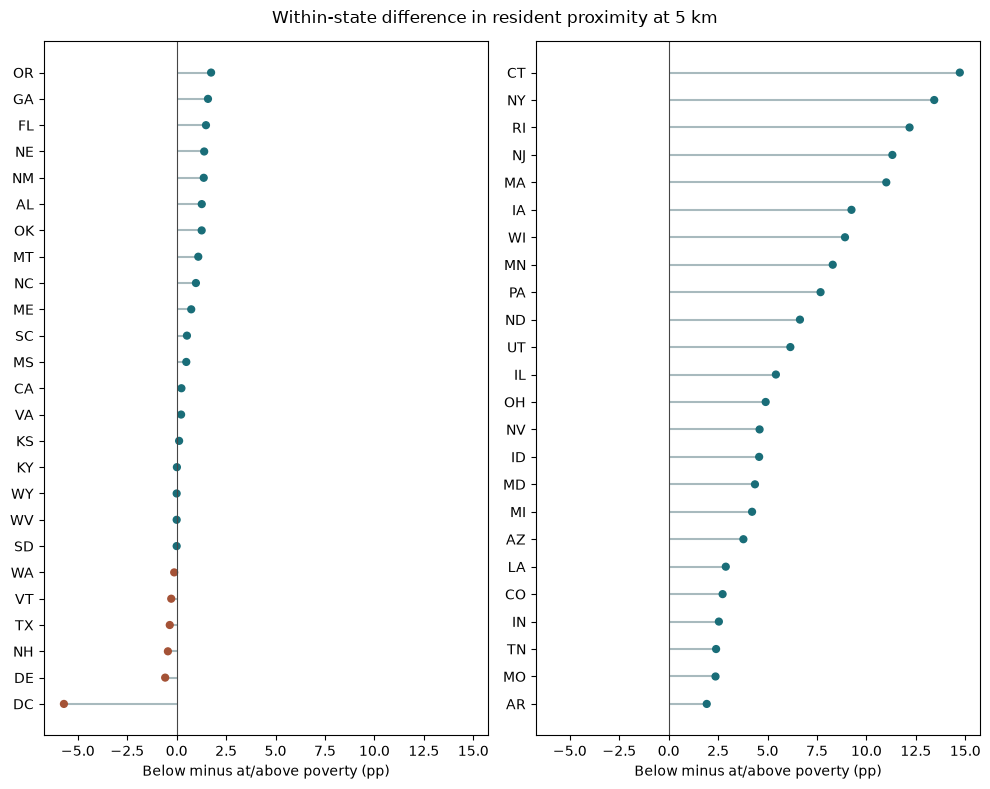

In [6]:
reach = pairs.loc[pairs.km.le(5)].copy()
reach["state"] = reach.geoid.str[:2].map(codes)
facility = (reach.groupby("state").agg(contributing_sites=("plant_id_eia","nunique"),
             tract_site_pairs=("geoid","size")).reset_index())
cross = reach.loc[reach.state.ne(reach.plant_state)].groupby("state").geoid.nunique()
scale = (t.loc[t.mw5.gt(0)].assign(mw_per_site=lambda v:v.mw5/v.n5)
         .groupby("state").agg(mean_sites_positive=("n5","mean"),
             median_mw_positive=("mw5","median"),mean_mw_per_site=("mw_per_site","mean")).reset_index())
detail = state_table.merge(facility,how="left",on="state").merge(scale,how="left",on="state")
detail["tracts_with_out_of_state_site"] = detail.state.map(cross).fillna(0).astype(int)
for field in ["contributing_sites","tract_site_pairs"]:
    detail[field] = detail[field].fillna(0).astype(int)
save_table(detail,"state_capacity_detail")
order = detail.sort_values("gap_pp")
fig,axs = plt.subplots(1,2,figsize=(10,8),sharex=True)
for ax,part in zip(axs,np.array_split(np.arange(len(order)),2)):
    s = order.iloc[part]
    ax.hlines(s.state,0,s.gap_pp,color="#a8babe")
    ax.scatter(s.gap_pp,s.state,color=np.where(s.gap_pp>=0,"#196d78","#a45236"),s=24,zorder=2)
    ax.axvline(0,color="#454545",lw=.8)
    ax.set_xlabel("Below minus at/above poverty (pp)")
fig.suptitle("Within-state difference in resident proximity at 5 km")
save_fig(fig,"state_gaps")

### Interpretation of this run
Across the 48 contiguous states and DC, 9,415 of 83,219 mapped tract centers had qualifying capacity within 5 km. The resident-weighted proximity estimate was 13.99% below poverty and 10.58% at or above poverty, a gap of +3.41 percentage points. These percentages assign everyone in a tract its center's proximity. The California gap alone was +0.24 points. The pooled gap includes differences within states as well as differences in where the two populations live across states.

Per 10-percentage-point higher tract poverty, the primary adjusted presence odds ratio was **1.380**. Among positive tracts, geometric mean MW differed by **+0.0%** (95% confidence interval -1.6% to +1.7%). The other radii change both the set of included facilities and the set of positive tracts. Density adjustment is a sensitivity check. These are infrastructure proximity measures; interpreting differences in actual exposure requires operating and emissions data.

The 543 tracts without usable population centers have unknown proximity. Center coordinates describe 2020 population geography and ACS counts are estimates for 2019–2023. Uncertainty intervals above condition on the tract data and may understate dependence among neighbors sharing a facility. County-equivalent grouping includes Connecticut planning regions and DC.

### Sources
[ACS table-based summary files](https://www.census.gov/programs-surveys/acs/data/summary-file.2023.html) · [2020 Census population centers](https://www.census.gov/geographies/reference-files/2020/geo/2020-centers-population.html) · [TIGER/Line and cartographic boundaries](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html) · [Gazetteer land areas](https://www.census.gov/geographies/reference-files/time-series/geo/gazetteer-files.html) · [PUDL](https://docs.catalyst.coop/pudl/en/latest/data_access.html).